# Automobile Sales Analysis — Recession Impact

**Role:** Data Analyst at XYZAutomotives, examining historical sales trends to understand how recessions have affected the business.

**Question:** how did automobile sales, by vehicle type, respond to each U.S. recession since 1980 — and which levers (advertising spend, price, unemployment, consumer confidence) moved with them?

This is a companion piece to [`automobile_sales_dashboard.py`](automobile_sales_dashboard.py) in this same project folder: this notebook is the static exploratory analysis, the dashboard is the interactive version of the same questions.


## About the Dataset

Monthly automobile sales and related variables (price, advertising spend, GDP, unemployment, consumer confidence, seasonality) from 1980–2023, broken out by vehicle type (SuperMiniCar, SmallFamilyCar, MediumFamilyCar, ExecutiveCar, Sports) and flagged for whether the month falls inside a U.S. recession:

- Recession 1 — 1980
- Recession 2 — 1981–82
- Recession 3 — 1991
- Recession 4 — 2000–01
- Recession 5 — late 2007–mid 2009
- Recession 6 — Feb–Apr 2020 (COVID-19)


## Setup


In [ ]:
%pip install pandas
%pip install numpy
%pip install seaborn
%pip install folium

In [2]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import folium

<ipython-input-2-107089beb3f3>:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


## Loading the Data


In [3]:
import requests
import io
import pandas as pd

# URL of the CSV file
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/d51iMGfp_t0QpO30Lym-dw/automobile-sales.csv"

# Fetch the data from the URL
response = requests.get(URL)

# Raise an error if the request failed
response.raise_for_status()

# Convert the response content into a readable format for pandas
csv_content = io.StringIO(response.text)

# Read the CSV data into a pandas dataframe
df = pd.read_csv(csv_content)

# Print confirmation
print('Data downloaded and read into a dataframe!')

# Optional: Show the first few rows of the dataframe
print(df.head())

Data downloaded and read into a dataframe!
         Date  Year Month  Recession  Consumer_Confidence  Seasonality_Weight  \
0  1980-01-31  1980   Jan          1               108.24                0.45   
1  1980-01-31  1980   Jan          1               108.24                0.45   
2  1980-01-31  1980   Jan          1               108.24                0.36   
3  1980-01-31  1980   Jan          1               108.24                0.38   
4  1980-02-29  1980   Feb          1                98.75                0.46   

   Price  Advertising_Expenditure  Competition    GDP  Growth_Rate  \
0  27704                   1417.5            7  60.22         0.01   
1  77270                    763.7            7  60.22         0.01   
2  19665                   1417.5            7  60.22         0.01   
3  36986                   1417.5            7  60.22         0.01   
4  26609                   2773.4            4  45.99        -0.31   

   unemployment_rate  Automobile_Sales     Vehicl

### A first look


In [4]:
df.describe()

,Year,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales
count,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000
mean,2001.520833,0.224432,101.210890,0.737756,41469.506155,2879.743655,6.118845,40.205748,-0.237074,2.441525,3164.160511
std,12.535031,0.417306,10.634092,0.286092,21388.409141,1175.338324,1.964292,16.291271,0.859691,1.108472,3640.137399
min,1980.000000,0.000000,73.900000,0.250000,15001.000000,494.200000,3.000000,12.510000,-4.230000,1.000000,40.000000
25%,1991.000000,0.000000,94.060000,0.500000,22039.000000,1872.000000,4.000000,27.210000,-0.570000,1.600000,923.000000
50%,2002.000000,0.000000,100.800000,0.810000,34957.500000,2883.500000,6.000000,39.420000,-0.005000,2.300000,2381.500000
75%,2012.000000,0.000000,108.320000,0.940000,57418.250000,3902.425000,8.000000,53.862500,0.392500,2.900000,4363.500000
max,2023.000000,1.000000,131.670000,1.500000,79998.000000,4983.000000,9.000000,70.370000,0.820000,6.000000,65645.000000


In [5]:
df.columns

Index(['Date', 'Year', 'Month', 'Recession', 'Consumer_Confidence',
       'Seasonality_Weight', 'Price', 'Advertising_Expenditure', 'Competition',
       'GDP', 'Growth_Rate', 'unemployment_rate', 'Automobile_Sales',
       'Vehicle_Type', 'City'],
      dtype='object')

## Sales Over Time — Where Do the Recessions Show Up?

A line chart of average automobile sales by year, with tick marks for every year and the two biggest recessions annotated directly on the plot.


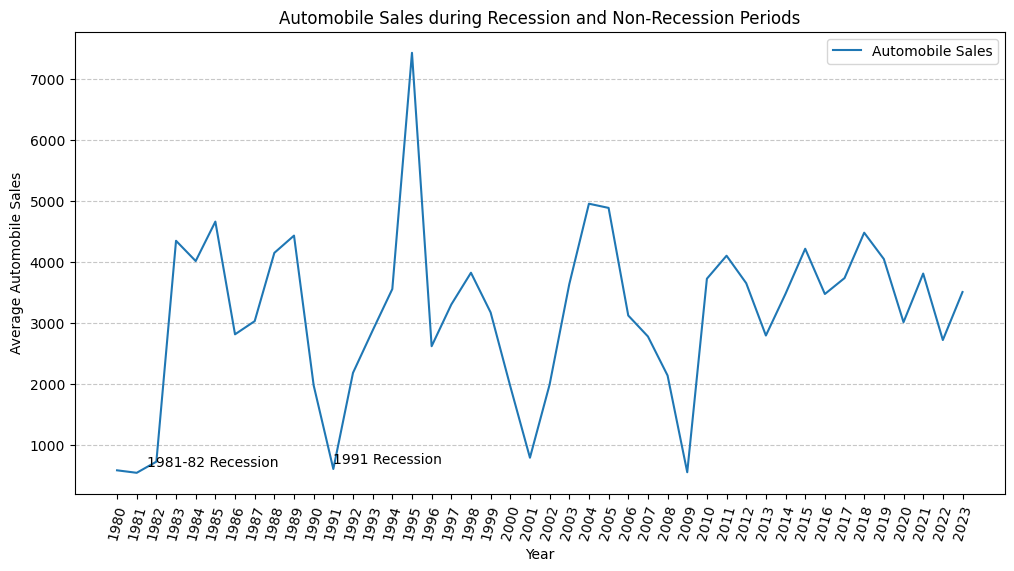

In [6]:
# Create data for plotting
df_line = df.groupby('Year')['Automobile_Sales'].mean()

# Create figure
plt.figure(figsize=(12, 6))
df_line.plot(kind='line')
plt.xticks(list(range(1980, 2024)), rotation=75)
plt.xlabel('Year')
plt.ylabel('Average Automobile Sales')
plt.title('Automobile Sales during Recession and Non-Recession Periods')
plt.text(1981.5, 650, '1981-82 Recession')
plt.text(1991, 700, '1991 Recession')
plt.legend(['Automobile Sales'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


## Advertising Spend vs. Sales — Outside of Recessions

How closely do advertising expenditure and sales actually track each other in normal economic conditions?


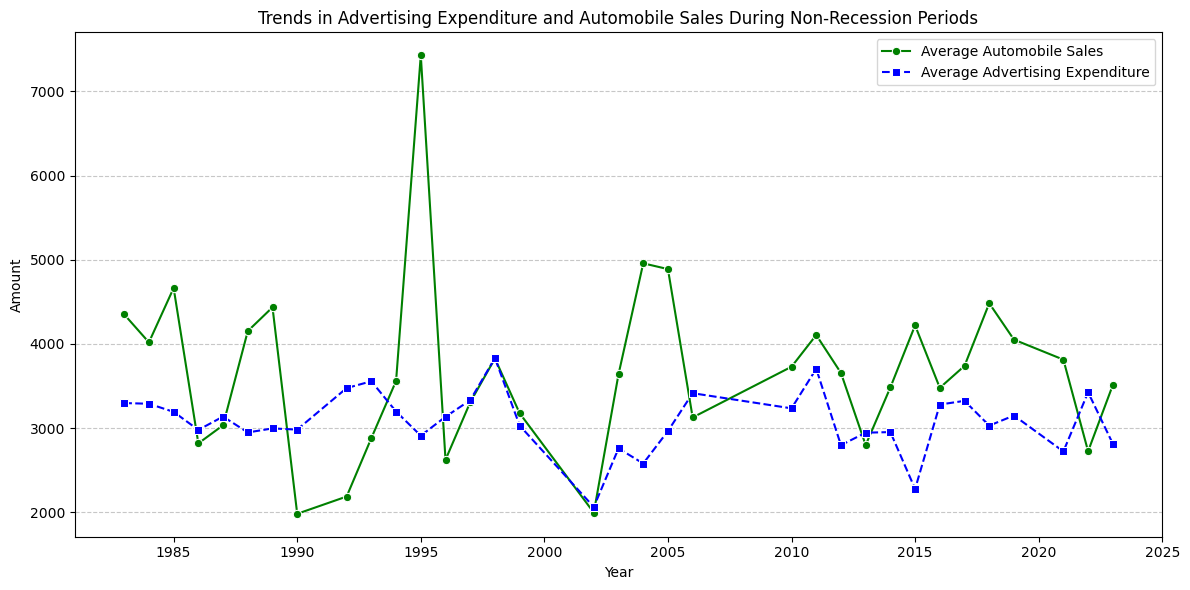

In [7]:
# Filter dataset for non-recession periods
df_non_rec = df[df['Recession'] == 0]

# Calculate average automobile sales and average advertising expenditure by year
df_trends = df_non_rec.groupby('Year', as_index=False).agg(
    Avg_Sales=('Automobile_Sales', 'mean'),
    Avg_Ad_Spend=('Advertising_Expenditure', 'mean')
)

# Plot line charts for sales and ad spend
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_trends, x='Year', y='Avg_Sales', marker='o', linestyle='-', color='green', label='Average Automobile Sales')
sns.lineplot(data=df_trends, x='Year', y='Avg_Ad_Spend', marker='s', linestyle='--', color='blue', label='Average Advertising Expenditure')

plt.xlabel('Year')
plt.ylabel('Amount')
plt.title('Trends in Advertising Expenditure and Automobile Sales During Non-Recession Periods')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Automobile sales are noticeably more volatile year-to-year than advertising expenditure during non-recession periods — spend tends to move in a narrower, steadier band while sales swing more with broader demand conditions. That's a useful caveat for XYZAutomotives: ad spend alone isn't a reliable dial for predicting sales, even outside of recessions.


## Recession vs. Non-Recession — the Headline Number


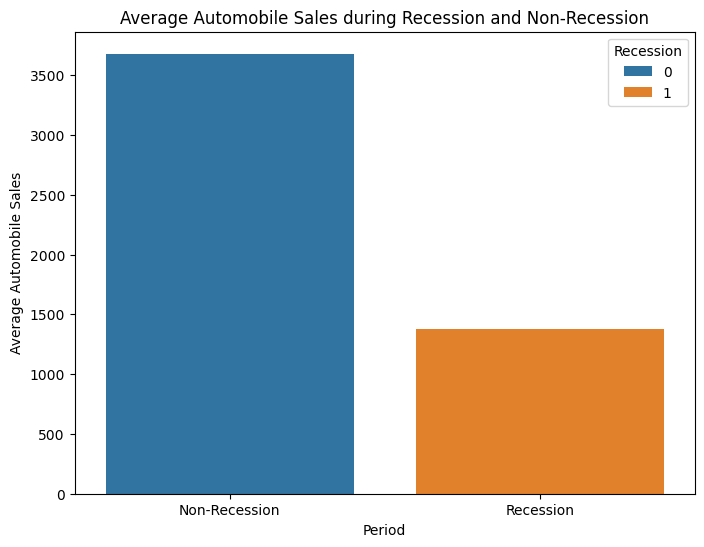

In [10]:
new_df = df.groupby('Recession')['Automobile_Sales'].mean().reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(x='Recession', y='Automobile_Sales', hue='Recession', data=new_df)
plt.xlabel('Period')
plt.ylabel('Average Automobile Sales')
plt.title('Average Automobile Sales during Recession and Non-Recession')
plt.xticks(ticks=[0, 1], labels=['Non-Recession', 'Recession'])
plt.show()

### Which vehicle types take the biggest hit?


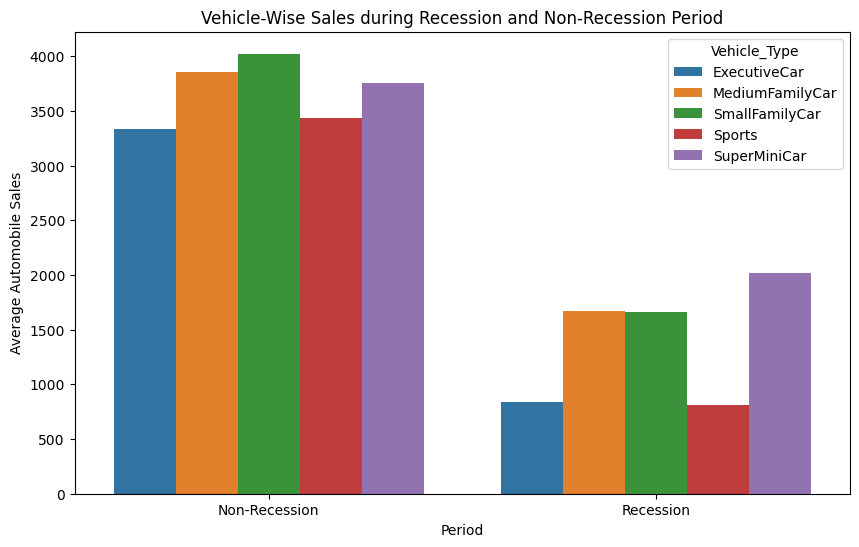

In [11]:
grouped_df = df.groupby(['Recession', 'Vehicle_Type'])['Automobile_Sales'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='Recession', y='Automobile_Sales', hue='Vehicle_Type', data=grouped_df)
plt.xticks(ticks=[0, 1], labels=['Non-Recession', 'Recession'])
plt.xlabel('Period')
plt.ylabel('Average Automobile Sales')
plt.title('Vehicle-Wise Sales during Recession and Non-Recession Period')
plt.show()

There's a clear, drastic decline in overall sales during recessions — but it isn't spread evenly across the lineup. ExecutiveCar and Sports are the most exposed vehicle types, which tracks with intuition: these are the more discretionary, higher-price purchases that buyers postpone first when the economy turns.


## GDP: Recession vs. Non-Recession Periods


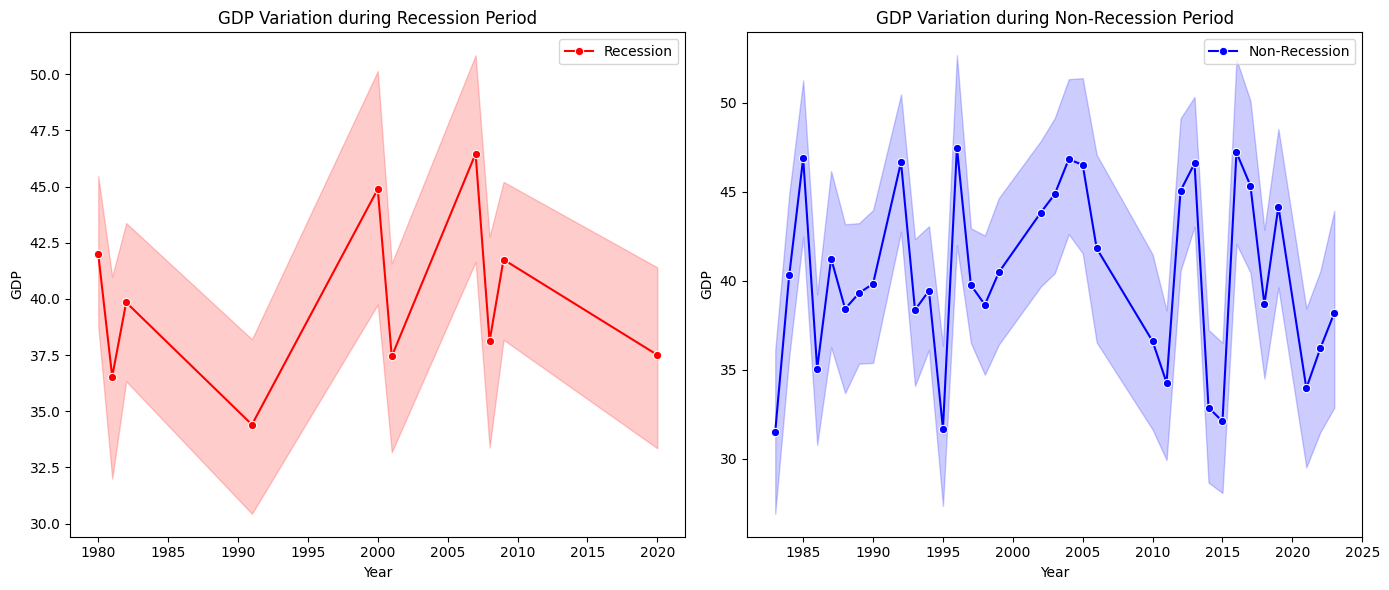

In [12]:
rec_data = df[df['Recession'] == 1]
non_rec_data = df[df['Recession'] == 0]

fig = plt.figure(figsize=(14, 6))

# Subplot 1: Recession Period
ax0 = fig.add_subplot(1, 2, 1)
sns.lineplot(x='Year', y='GDP', data=rec_data, label='Recession', ax=ax0, color='red', marker='o')
ax0.set_xlabel('Year')
ax0.set_ylabel('GDP')
ax0.set_title('GDP Variation during Recession Period')

# Subplot 2: Non-Recession Period
ax1 = fig.add_subplot(1, 2, 2)
sns.lineplot(x='Year', y='GDP', data=non_rec_data, label='Non-Recession', ax=ax1, color='blue', marker='o')
ax1.set_xlabel('Year')
ax1.set_ylabel('GDP')
ax1.set_title('GDP Variation during Non-Recession Period')

plt.tight_layout()
plt.show()

GDP runs consistently lower and more volatile during recession periods than outside them — unsurprising on its own, but useful as a sanity check that the `Recession` flag in this dataset lines up with the macroeconomic conditions it's supposed to represent.


## Does Seasonality Matter Outside of Recessions?

A bubble plot of monthly sales, sized and colored by the dataset's seasonality weight.


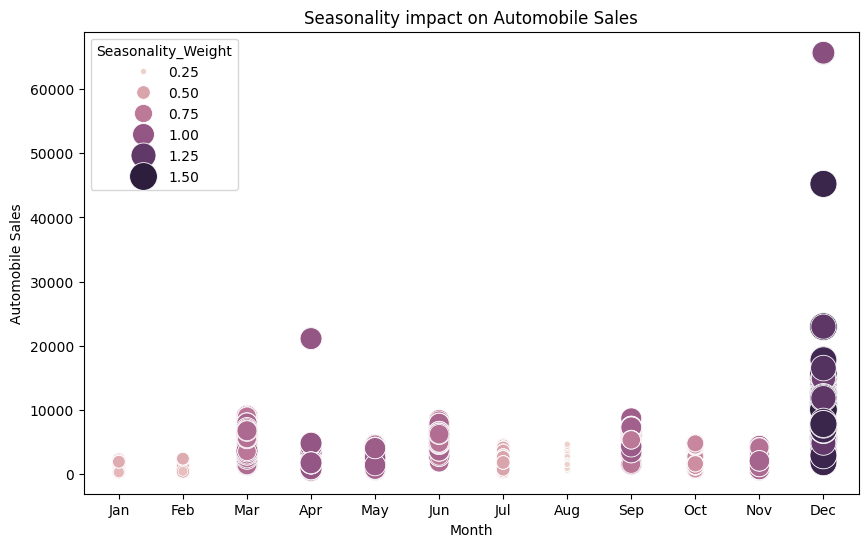

In [13]:
non_rec_data = df[df['Recession'] == 0]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=non_rec_data, 
    x='Month', 
    y='Automobile_Sales', 
    size='Seasonality_Weight', 
    hue='Seasonality_Weight',
    sizes=(20, 400),
    legend='brief'
)

plt.xlabel('Month')
plt.ylabel('Automobile Sales')
plt.title('Seasonality impact on Automobile Sales')
plt.show()

Seasonality doesn't move overall sales volume much — bubble sizes are fairly consistent across months. What it does appear to shift is the *mix*: certain months lean toward different vehicle types, which matters more for inventory planning than for a top-line sales forecast.


## What Drives Sales *During* a Recession?

### Consumer confidence


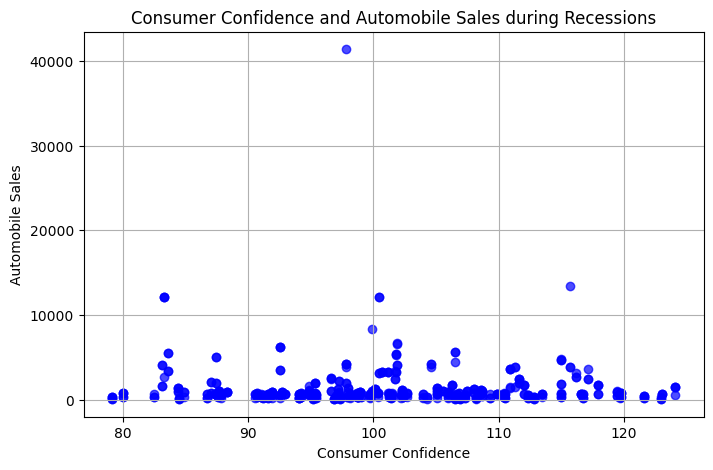

In [14]:
rec_data = df[df['Recession'] == 1]

plt.figure(figsize=(8, 5))
plt.scatter(rec_data['Consumer_Confidence'], rec_data['Automobile_Sales'], color='blue', alpha=0.7)
plt.xlabel('Consumer Confidence')
plt.ylabel('Automobile Sales')
plt.title('Consumer Confidence and Automobile Sales during Recessions')
plt.grid(True)
plt.show()

### Vehicle price


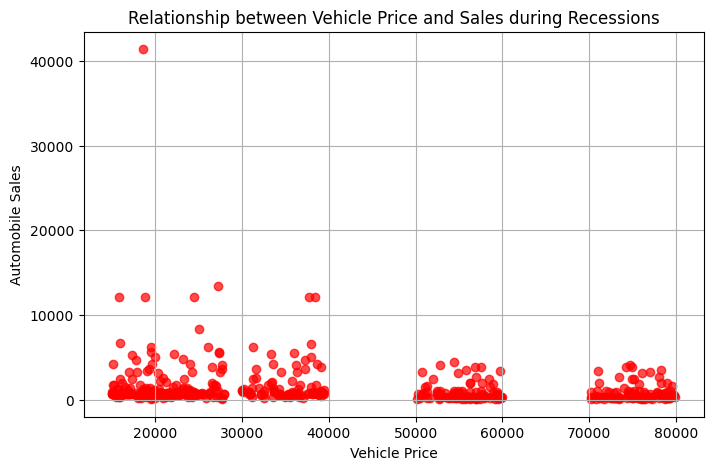

In [15]:
rec_data = df[df['Recession'] == 1]

plt.figure(figsize=(8, 5))
plt.scatter(rec_data['Price'], rec_data['Automobile_Sales'], color='red', alpha=0.7)
plt.xlabel('Vehicle Price')
plt.ylabel('Automobile Sales')
plt.title('Relationship between Vehicle Price and Sales during Recessions')
plt.grid(True)
plt.show()

During recessions, higher consumer confidence tends to line up with stronger sales — buyers who feel more secure about the economy are more willing to make a big purchase even in a downturn. Price shows the opposite pull, as expected: pricier vehicles sell less well precisely when budgets are tightest. Together, these two are a reasonable proxy for "who still buys a car in a recession, and what do they buy."


## Advertising Spend: Recession vs. Non-Recession


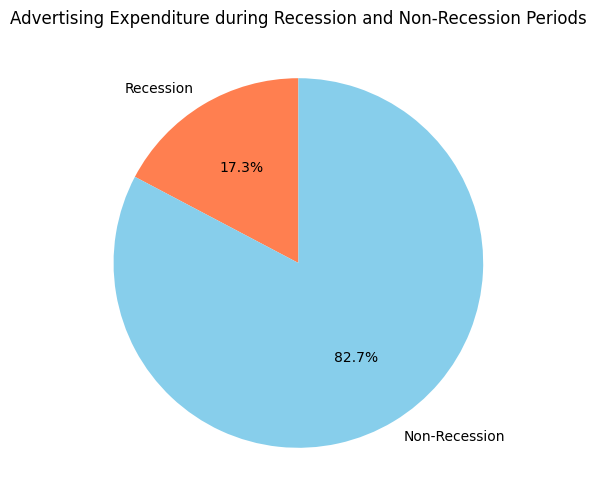

In [16]:
Rdata = df[df['Recession'] == 1]
NRdata = df[df['Recession'] == 0]

RAtotal = Rdata['Advertising_Expenditure'].sum()
NRAtotal = NRdata['Advertising_Expenditure'].sum()

plt.figure(figsize=(8, 6))
labels = ['Recession', 'Non-Recession']
sizes = [RAtotal, NRAtotal]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['coral', 'skyblue'])
plt.title('Advertising Expenditure during Recession and Non-Recession Periods')
plt.show()

XYZAutomotives spends considerably more on advertising during non-recession periods than during recessions — which raises a real strategic question rather than just describing the past: is cutting ad spend *during* downturns the right call, or does it leave sales more exposed exactly when competitors might be pulling back too?


## Where Does Recession Ad Spend Actually Go?

Breaking the recession-period advertising total down by vehicle type.


In [ ]:
Rdata = df[df['Recession'] == 1]
VTexpenditure = Rdata.groupby('Vehicle_Type')['Advertising_Expenditure'].sum()

plt.figure(figsize=(8, 8))
plt.pie(VTexpenditure.values, labels=VTexpenditure.index, autopct='%1.1f%%', startangle=90)
plt.title('Share of Each Vehicle Type in Total Expenditure during Recessions')
plt.show()

During recessions, advertising tends to concentrate on the lower-price, higher-volume vehicle types rather than the discretionary ones — the opposite of where sales actually decline most (Sports and ExecutiveCar, from the earlier section). That gap between where the ad budget goes and where sales are most at risk is worth a second look.


## Unemployment's Effect on Vehicle Type and Sales


In [ ]:
df_rec = df[df['Recession'] == 1]

plt.figure(figsize=(16, 6))
sns.lineplot(
    data=df_rec,
    x='unemployment_rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    marker='o'
)
plt.title('Effect of Unemployment Rate on Vehicle Type and Sales')
plt.xlabel('Unemployment Rate')
plt.ylabel('Average Automobile Sales')
plt.legend(title='Vehicle Type')
plt.tight_layout()
plt.show()

Sales decline as unemployment rises, with a sharper drop once it climbs past roughly 3%. SuperMiniCar, SmallFamilyCar, and MediumFamilyCar are the most volatile lines on this chart — these budget-conscious segments swing the most as job security becomes less certain, more than the higher-end vehicle types do.


## Key Findings & Recommendation

- **Uneven impact:** ExecutiveCar and Sports absorb the biggest sales declines in a recession, yet don't receive a corresponding cut in advertising during those periods — spend stays concentrated on the segments that were already holding up better.
- **Leading indicators:** consumer confidence and unemployment both move with recession-period sales in the expected direction, and unemployment in particular shows a sharper break point once it crosses ~3% — a threshold worth monitoring as an early signal.
- **Advertising ROI question:** overall ad spend drops sharply in recessions even though sales are more volatile then, not less — worth testing whether maintaining (or reallocating) spend toward the hardest-hit segments during downturns would soften the sales decline.

**Recommendation:** XYZAutomotives should treat unemployment rate as a leading trigger for reviewing advertising allocation by vehicle type, rather than cutting spend uniformly once a recession is already underway.

*Note: the optional interactive-map task from the original assignment (recession-period sales by region) is intentionally left out here to keep this notebook focused and fully working end to end — happy to add it back in if a geographic view becomes useful.*


---
*Dataset and task structure adapted from IBM's "Data Visualization with Python" course (Automobile Sales final assignment, Part 1). Analysis and code completed independently.*
